In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("aavigan/cleveland-clinic-heart-disease-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cleveland-clinic-heart-disease-dataset' dataset.
Path to dataset files: /kaggle/input/cleveland-clinic-heart-disease-dataset


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import sklearn as sk
import matplotlib.pyplot as plt
import os

# List the contents of the downloaded directory to find the CSV file
dataset_files = os.listdir(path)
print(f"Files in the dataset directory: {dataset_files}")

# Assuming the CSV file is named 'heart.csv' or similar, find it.
# You might need to adjust 'heart.csv' if the actual filename is different.
csv_file = [f for f in dataset_files if f.endswith('.csv')][0]
full_file_path = os.path.join(path, csv_file)

df = pd.read_csv(full_file_path)
df.head()

Files in the dataset directory: ['processed_cleveland.csv']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0


In [ ]:
df = pd.read_csv('/kaggle/input/cleveland-clinic-heart-disease-dataset/processed_cleveland.csv')
df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0


In [ ]:
print(df.isnull().sum())
print(f"Total missing: {df.isnull().sum().sum()}")
print(f"Total rows: {len(df)}")

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64
Total missing: 0
Total rows: 303


In [ ]:
print("Question mark values per column:")
for col in df.columns:
  # count is for what
    count = (df[col] == '?').sum()
    if count > 0:
        print(f"{col}: {count} question marks")

Question mark values per column:
ca: 4 question marks
thal: 2 question marks


### Exploratory Data Analysis (EDA)

Let's start by understanding the basic structure and distributions of our dataset. We'll categorize features into numerical and categorical types and then visualize their distributions.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Display basic information about the DataFrame
print("DataFrame Info:")
df.info()
#drop and clean

df = df.dropna()


# Display descriptive statistics for numerical columns
print("\nDescriptive Statistics:")
display(df.describe())

# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"\nNumerical Columns: {numerical_cols}")
print(f"Categorical Columns: {categorical_cols}")

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  num       303 non-null    int64  
dtypes: float64(1), int64(11), object(2)
memory usage: 33.3+ KB

Descriptive Statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,4.000000



Numerical Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'num']
Categorical Columns: ['ca', 'thal']


#### Univariate Analysis of Numerical Features

We will visualize the distribution of each numerical feature using histograms and box plots to check for skewness, outliers, and central tendency.

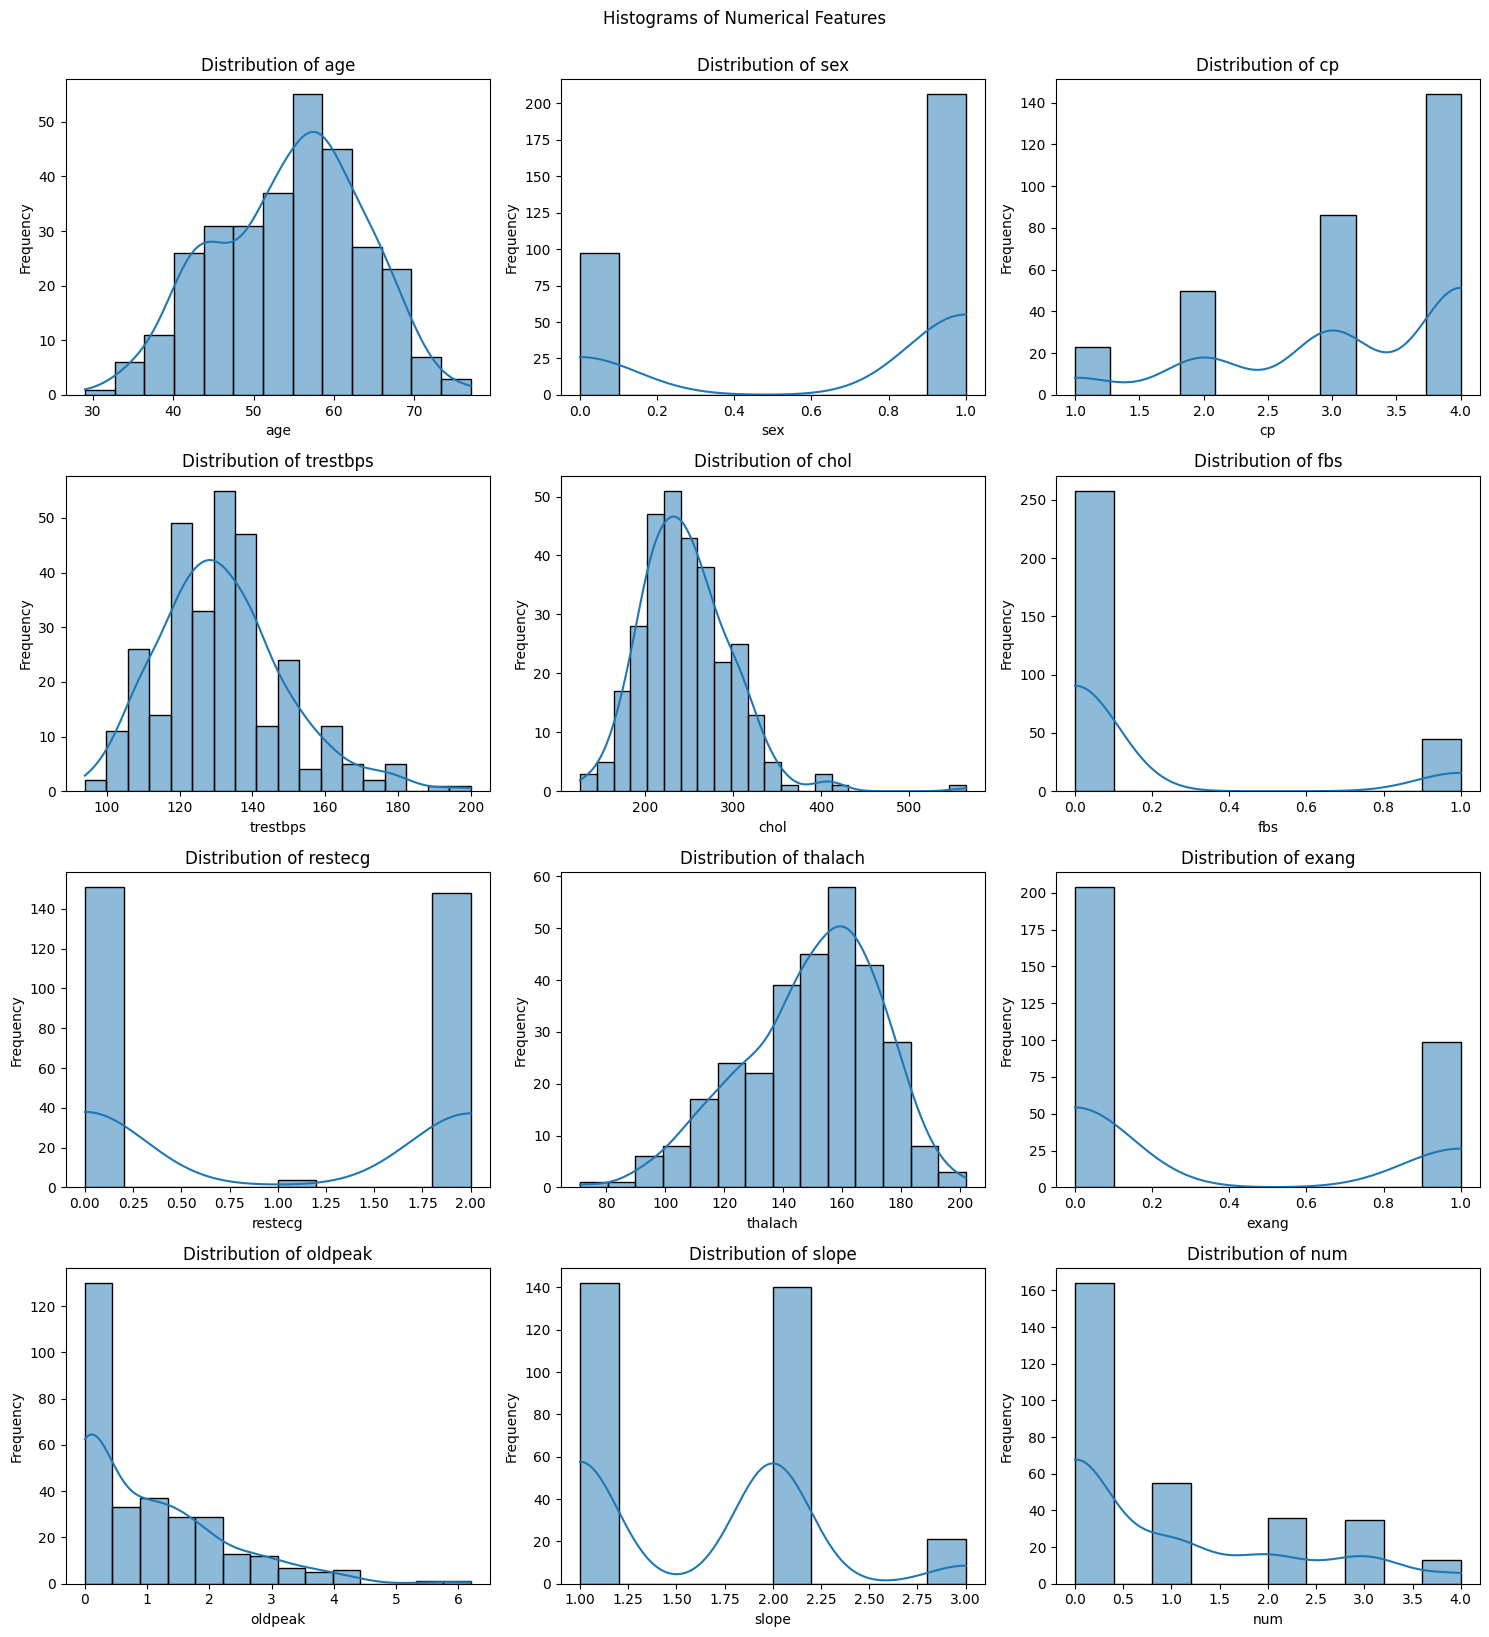

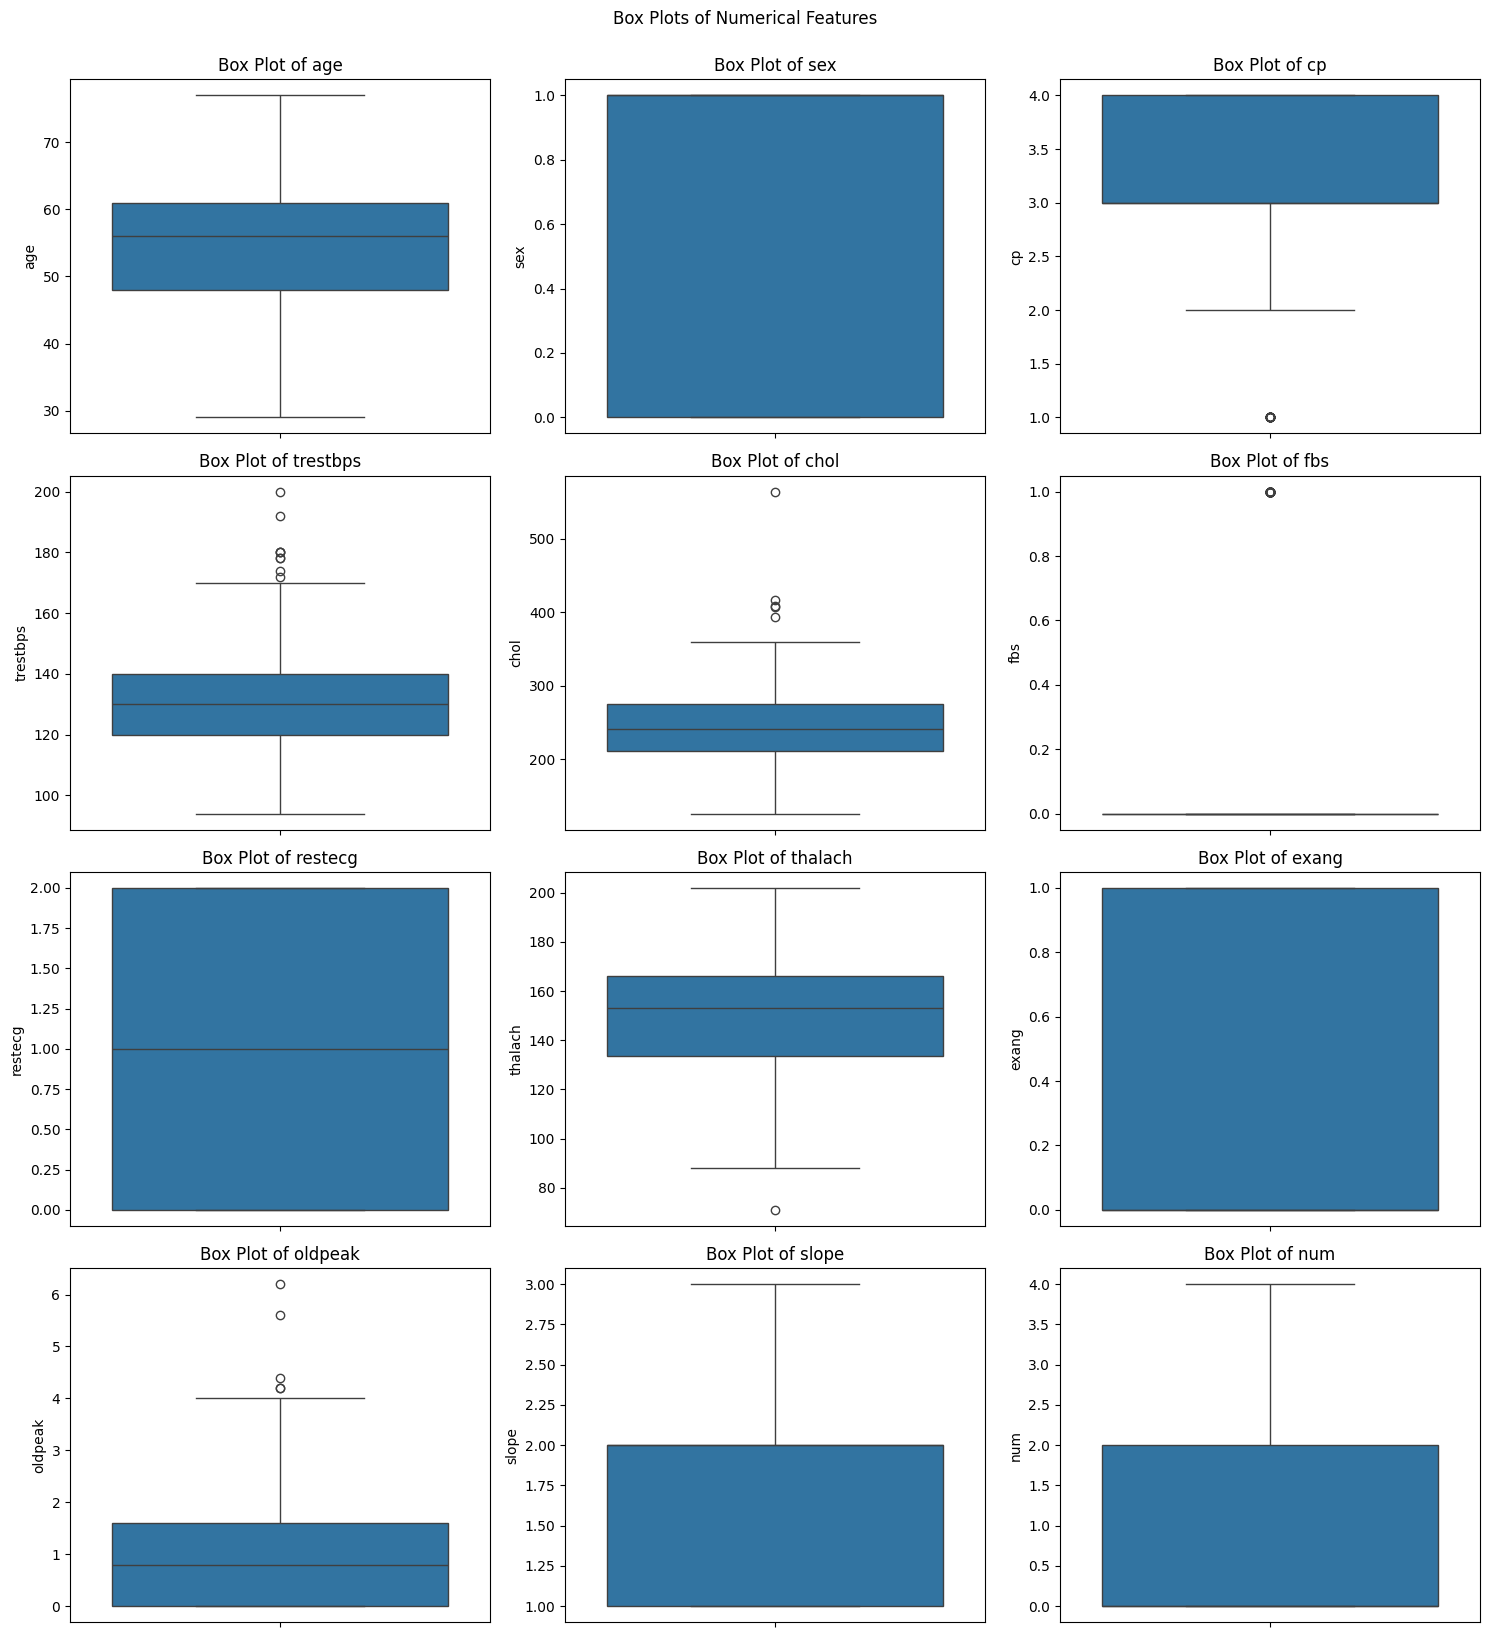

In [ ]:
if numerical_cols:
    # Determine number of rows and columns for subplots
    n_numerical = len(numerical_cols)
    n_cols = 3  # Adjust as needed for better layout
    n_rows = (n_numerical + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = axes.flatten() # Flatten in case of single row/column

    for i, col in enumerate(numerical_cols):
        sns.histplot(df[col].dropna(), kde=True, ax=axes[i])
        axes[i].set_title(f'Distribution of {col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frequency')

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.suptitle('Histograms of Numerical Features', y=1.02) # Add a super title
    plt.show()

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(numerical_cols):
        sns.boxplot(y=df[col].dropna(), ax=axes[i])
        axes[i].set_title(f'Box Plot of {col}')
        axes[i].set_ylabel(col)

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.suptitle('Box Plots of Numerical Features', y=1.02)
    plt.show()
else:
    print("No numerical columns to visualize.")

#### Univariate Analysis of Categorical Features

We will visualize the distribution of each categorical feature using count plots to see the frequency of each category.

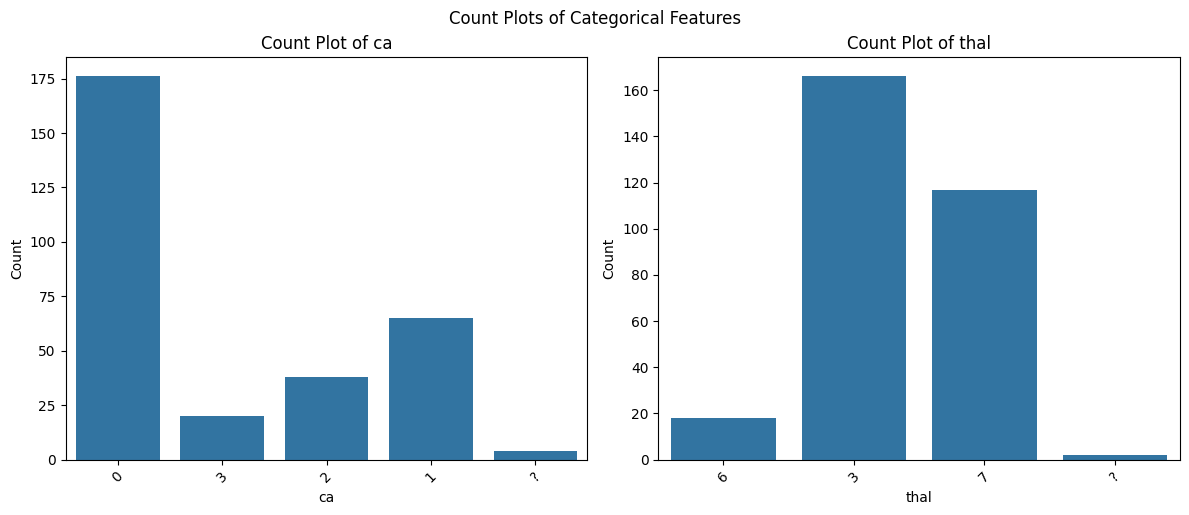

In [ ]:
if categorical_cols:
    n_categorical = len(categorical_cols)
    n_cols = 2 # Adjust as needed
    n_rows = (n_categorical + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(categorical_cols):
        sns.countplot(x=df[col].dropna(), ax=axes[i])
        axes[i].set_title(f'Count Plot of {col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Count')
        axes[i].tick_params(axis='x', rotation=45) # Rotate x-axis labels if they overlap

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.suptitle('Count Plots of Categorical Features', y=1.02)
    plt.show()
else:
    print("No categorical columns to visualize.")

#### Value Counts for Categorical Features

Let's examine the unique values and their frequencies for the categorical columns to further understand their distribution and potential imbalances.

In [ ]:
print("\nValue counts for 'ca' column:")
display(df['ca'].value_counts())

print("\nValue counts for 'thal' column:")
display(df['thal'].value_counts())


Value counts for 'ca' column:


,count
ca,
0,176
1,65
2,38
3,20
?,4



Value counts for 'thal' column:


,count
thal,
3,166
7,117
6,18
?,2


#### Checking Dataset Balance: Value Counts for All Categorical and Target Columns

Let's check the distribution of values across all categorical columns and the potential target variable `num` to assess dataset balance. This helps identify if any classes are underrepresented, which can be important for model training.

In [ ]:
print("\nValue counts for 'sex' column:")
display(df['sex'].value_counts())

print("\nValue counts for 'cp' column:")
display(df['cp'].value_counts())

print("\nValue counts for 'fbs' column:")
display(df['fbs'].value_counts())

print("\nValue counts for 'restecg' column:")
display(df['restecg'].value_counts())

print("\nValue counts for 'exang' column:")
display(df['exang'].value_counts())

print("\nValue counts for 'slope' column:")
display(df['slope'].value_counts())

print("\nValue counts for 'num' (Target Variable) column:")
display(df['num'].value_counts())


Value counts for 'sex' column:


,count
sex,
1,206
0,97



Value counts for 'cp' column:


,count
cp,
4,144
3,86
2,50
1,23



Value counts for 'fbs' column:


...

,count
exang,
0,204
1,99



Value counts for 'slope' column:


,count
slope,
1,142
2,140
3,21



Value counts for 'num' (Target Variable) column:


,count
num,
0,164
1,55
2,36
3,35
4,13


#### Summary of Value Counts with Percentages for All Columns

Let's get a comprehensive overview of the distribution of values across all columns, including their percentages, to assess the balance of the dataset more effectively.

In [ ]:
print("\n--- Value Counts and Percentages for All Columns ---")
for col in df.columns:
    print(f"\nValue counts for '{col}' column:")
    counts = df[col].value_counts()
    percentages = df[col].value_counts(normalize=True) * 100
    summary_df = pd.DataFrame({'Count': counts, 'Percentage': percentages.round(2).astype(str) + '%'})
    display(summary_df)


#### Correlation Heatmap of All Features

Let's visualize the correlation matrix to understand the linear relationships between all numerical features in the dataset. This can help identify highly correlated features which might be redundant or give insights into multivariate relationships.

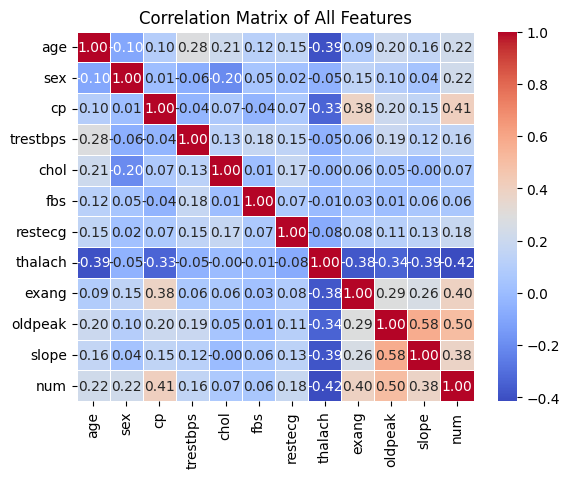

In [ ]:
import matplotlib.pyplot as plt
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of All Features')
plt.show()

#### Summarizing 'Age' into Categories

To get a more generalized view of age distribution, we'll categorize the 'age' column into 'Young', 'Teen', 'Adult', and 'Elderly' groups and then display their value counts and percentages.

In [ ]:
# Define age bins and labels
age_bins = [0, 19, 35, 55, 100]
age_labels = ['Young', 'Teen', 'Adult', 'Elderly']

# Create a new 'age_group' column based on these bins
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=False)

# Display value counts and percentages for the new 'age_group' column
print("\nValue counts for 'age_group' column:")
counts = df['age_group'].value_counts()
percentages = df['age_group'].value_counts(normalize=True) * 100
summary_df_age = pd.DataFrame({'Count': counts, 'Percentage': percentages.round(2).astype(str) + '%'})
display(summary_df_age)


Value counts for 'age_group' column:


,Count,Percentage
age_group,,
Elderly,160,52.81%
Adult,140,46.2%
Teen,3,0.99%
Young,0,0.0%


## feature selection  ##

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn as sk
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv('/kaggle/input/cleveland-clinic-heart-disease-dataset/processed_cleveland.csv')

# Replace '?' with NaN in 'ca' and 'thal' columns
df['ca'] = df['ca'].replace('?', np.nan)
df['thal'] = df['thal'].replace('?', np.nan)

# Convert 'ca' and 'thal' to numeric, coercing errors will turn non-numeric values into NaN
df['ca'] = pd.to_numeric(df['ca'], errors='coerce')
df['thal'] = pd.to_numeric(df['thal'], errors='coerce')

# Drop rows with NaN values (including those introduced by '?' replacement)
df = df.dropna()

# Ensure 'num' is treated as a categorical target for classification
df['num'] = df['num'].astype('category')

Feature Importances (Random Forest):


,Feature,Importance
7,thalach,0.138926
9,oldpeak,0.117851
0,age,0.115244
4,chol,0.113633
3,trestbps,0.099319
11,ca,0.094761
12,thal,0.082430
2,cp,0.075682
8,exang,0.046423
10,slope,0.042554


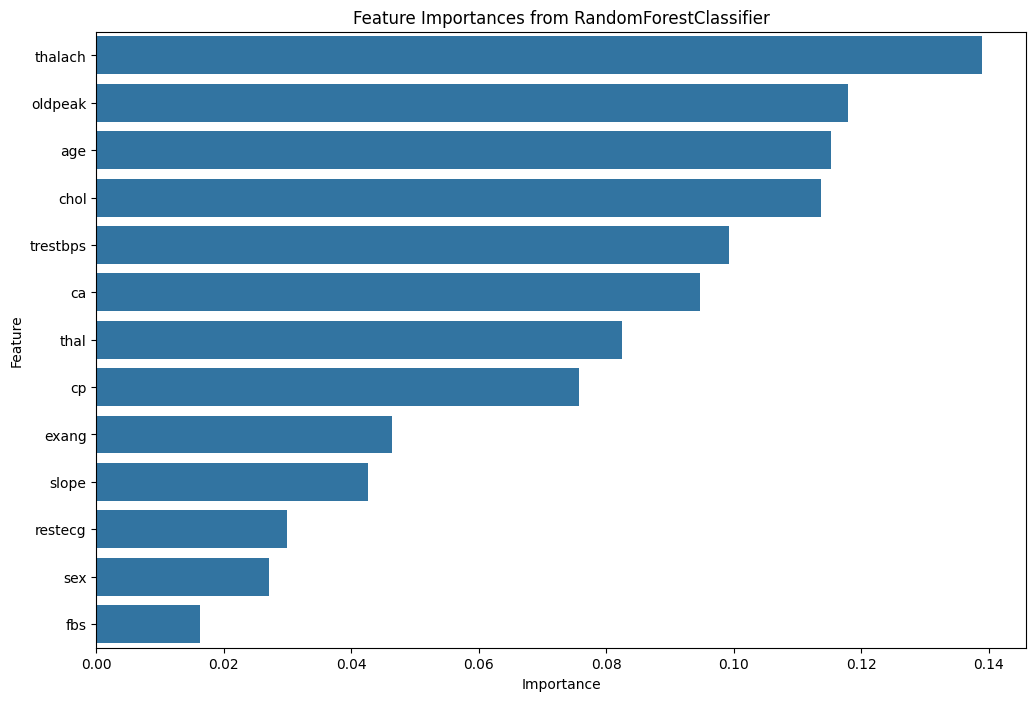

In [ ]:
# Define features (X) and target (y) so x remove y the target
X = df.drop('num', axis=1)
y = df['num']

# Initialize a RandomForestClassifier
# Using a fixed random_state for reproducibility
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
rf_model.fit(X, y)

# Get feature importances
feature_importances = rf_model.feature_importances_

# Create a DataFrame for better visualization
features_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importances
})

# Sort features by importance
features_df = features_df.sort_values(by='Importance', ascending=False)

# Display feature importances
print("Feature Importances (Random Forest):")
display(features_df)

# Visualize feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=features_df)
plt.title('Feature Importances from RandomForestClassifier')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

### Interpreting SHAP Summary Plots

We generated two types of SHAP summary plots, each offering a different perspective on feature importance:

1.  **SHAP Feature Importance (Absolute Mean Bar Plot):**
    *   This plot (the bar chart) shows the **average absolute SHAP value** for each feature across all predictions. The longer the bar, the more impact the feature has on the model's output *on average*. It's similar to the Random Forest feature importance but derived from SHAP values, giving a global view of importance.

2.  **SHAP Summary Plot (Detailed Scatter Plot):**
    *   This plot (the scatter plot) provides a more granular view:
        *   **Vertical Axis:** Lists the features by their importance (most important at the top, based on mean absolute SHAP value).
        *   **Horizontal Axis:** Represents the SHAP value. A positive SHAP value means the feature is pushing the prediction higher, and a negative value means it's pushing it lower.
        *   **Color:** The color of each dot indicates the original value of the feature (e.g., red for high values, blue for low values).
        *   **Each Dot:** Represents a single observation (patient) in the dataset.

    *   **How to interpret the detailed plot:**
        *   **For a specific feature (row):** Observe the spread of dots. If high (red) feature values tend to correspond to high (positive) SHAP values, it means high values of that feature increase the likelihood of the positive outcome (e.g., presence of heart disease). Conversely, if low (blue) values correspond to high SHAP values, low feature values increase the positive outcome.
        *   **Overall:** This plot helps us understand not just *which* features are important, but also *how* they influence the predictions (e.g., does a high 'thalach' increase or decrease the risk of heart disease according to the model?).

These plots allow us to enumerate and clarify the importance and directional impact of each feature, going beyond a simple 'importance score' to understand the nature of that importance.

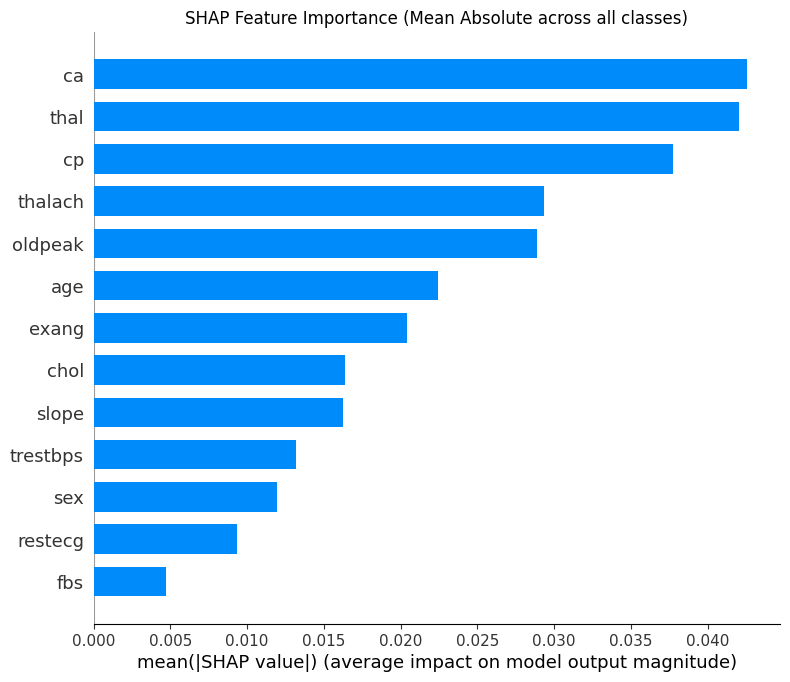

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt

# Ensure X is a NumPy array for SHAP computations
X_for_shap = X.values

# Create a SHAP TreeExplainer using the trained RandomForestClassifier model
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values for the dataset
# For multi-class classification, `explainer.shap_values` returns a list of arrays
# (one for each class), where each array has shape (n_samples, n_features).
# However, the kernel state indicates a 3D numpy array of shape (n_samples, n_features, n_classes).
# We will handle both possibilities to ensure compatibility.

# Calculate SHAP values
shap_values = explainer.shap_values(X_for_shap)

# If shap_values is a list of arrays (common for multi-class TreeExplainer),
# convert it to a 3D numpy array for consistent indexing.
if isinstance(shap_values, list):
    shap_values = np.array(shap_values).transpose(1, 2, 0) # Reshape to (n_samples, n_features (two sets), n_classes)

# 1. SHAP Feature Importance (Absolute Mean Bar Plot across all classes)
# To get a single bar plot representing overall feature importance, we calculate
# the mean of the absolute SHAP values across all classes for each sample-feature pair.
# This results in a (n_samples, n_features) array.
shap_values_for_overall_bar_plot = np.mean(np.abs(shap_values), axis=2)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_for_overall_bar_plot, X, plot_type="bar", feature_names=X.columns, show=False)
plt.title('SHAP Feature Importance (Mean Absolute across all classes)')
plt.show()



Generating detailed SHAP summary plots for each class:


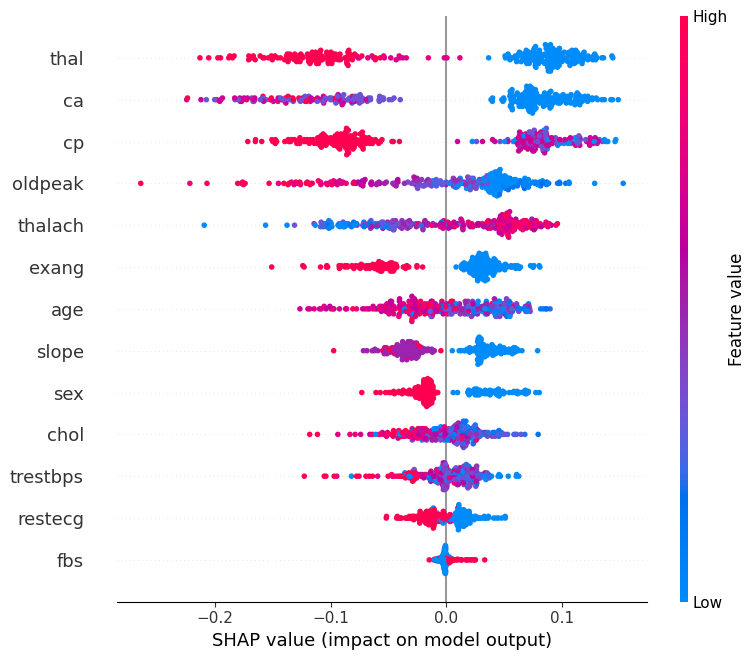

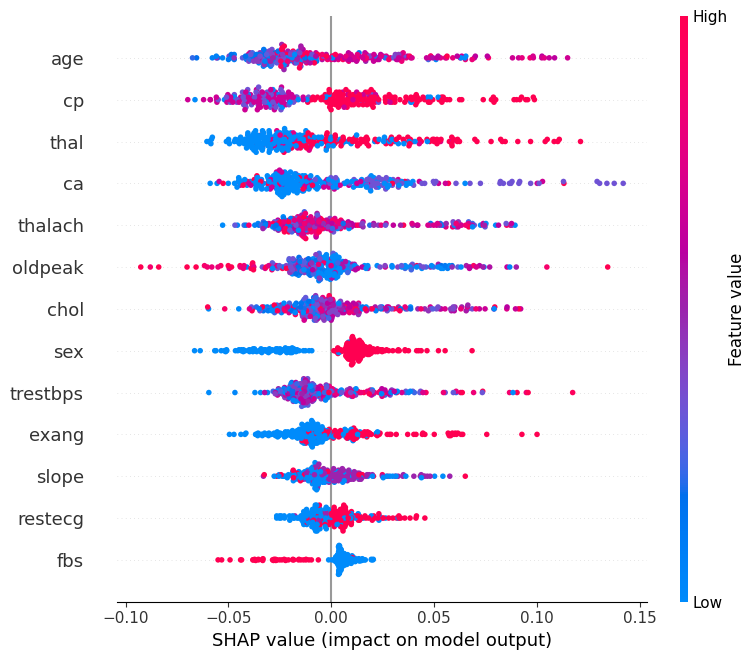

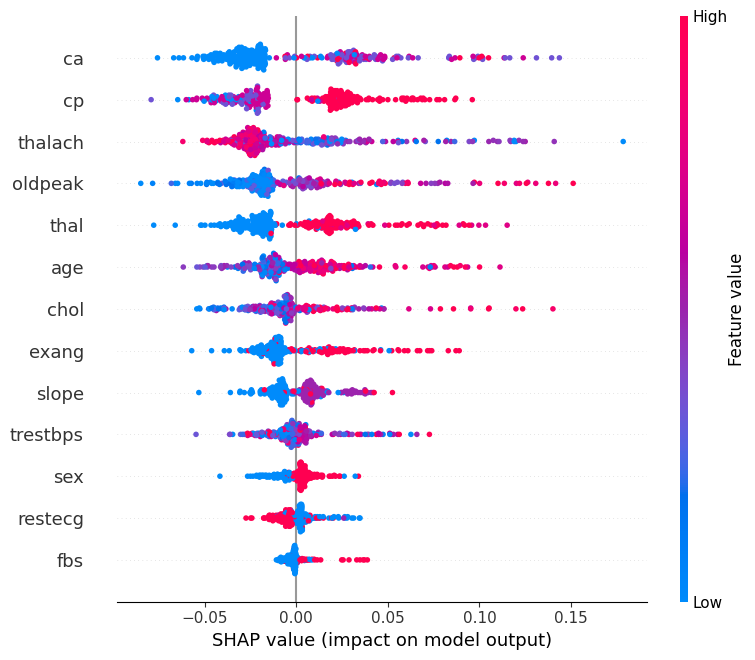

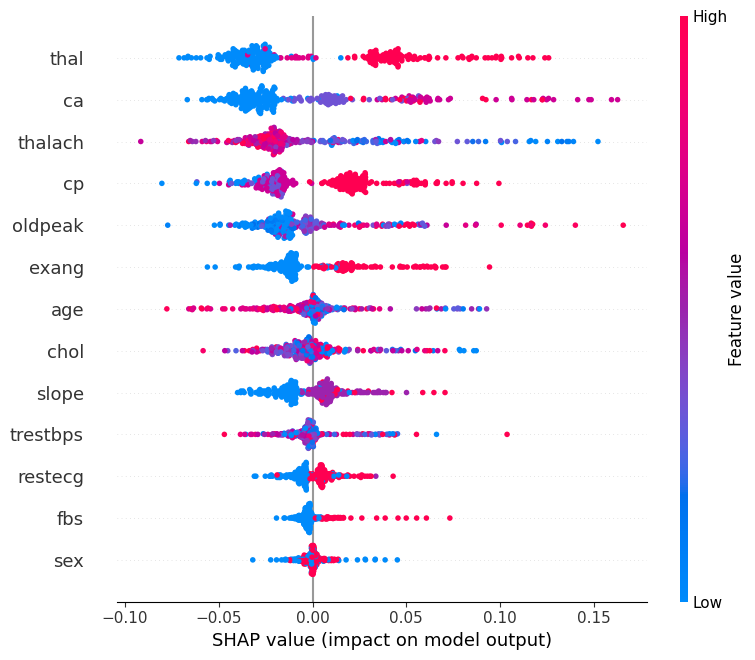

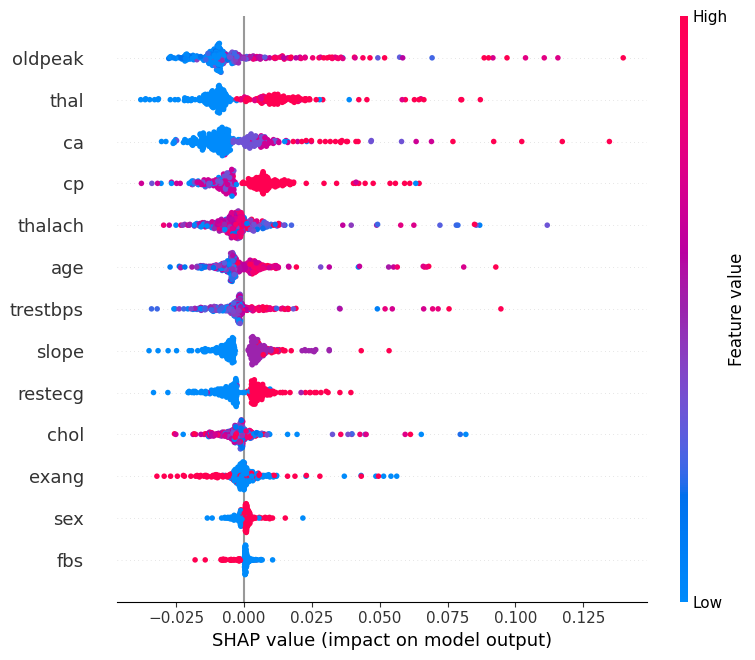

In [ ]:
# 2. SHAP Summary Plot (Detailed Scatter Plot) - for each class
# For detailed scatter plots,
# Each plot uses SHAP values specific to that class, which has shape (n_samples, n_features).
num_classes = len(rf_model.classes_)

print("\nGenerating detailed SHAP summary plots for each class:")
for i, class_label in enumerate(rf_model.classes_):
    plt.figure(figsize=(12, 8))
    # Select SHAP values for the current class (i-th class)
    shap_values_for_class_i = shap_values[:, :, i]
    shap.summary_plot(shap_values_for_class_i, X, feature_names=X.columns, show=False, title=f"SHAP Summary Plot for Class: {class_label}")
    plt.show()


## model ##

Random Forest Top Features (ranked):
['thalach', 'oldpeak', 'age', 'chol', 'trestbps', 'ca', 'thal', 'cp', 'exang', 'slope', 'restecg', 'sex', 'fbs']

SHAP Global Top Features (ranked by mean absolute SHAP value across all classes):
['ca', 'thal', 'cp', 'thalach', 'oldpeak', 'age', 'exang', 'chol', 'slope', 'trestbps', 'sex', 'restecg', 'fbs']

Top 5 Most Impactful Features (RF and SHAP agreement): ['thalach', 'oldpeak', 'age', 'chol', 'trestbps']

Performing EDA on the identified top 5 features...

--- EDA for Feature: thalach ---


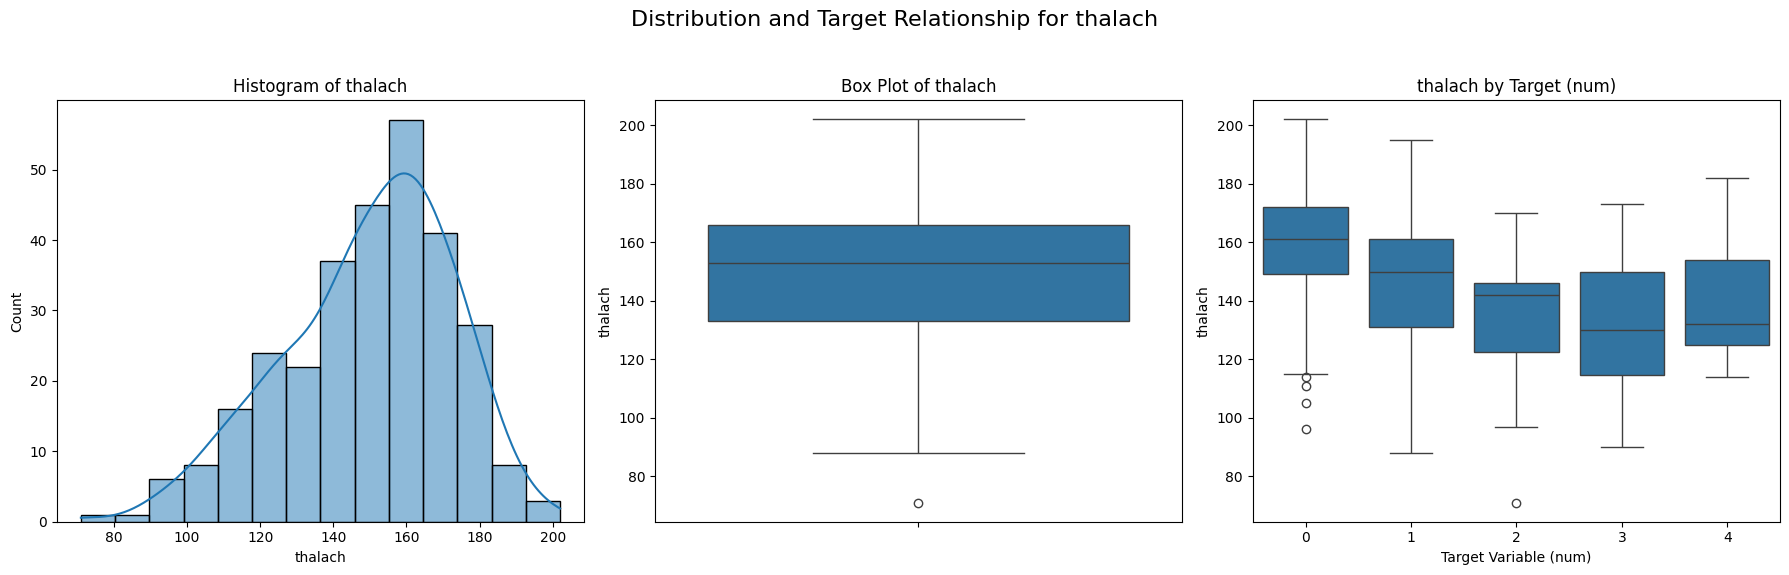


--- EDA for Feature: oldpeak ---


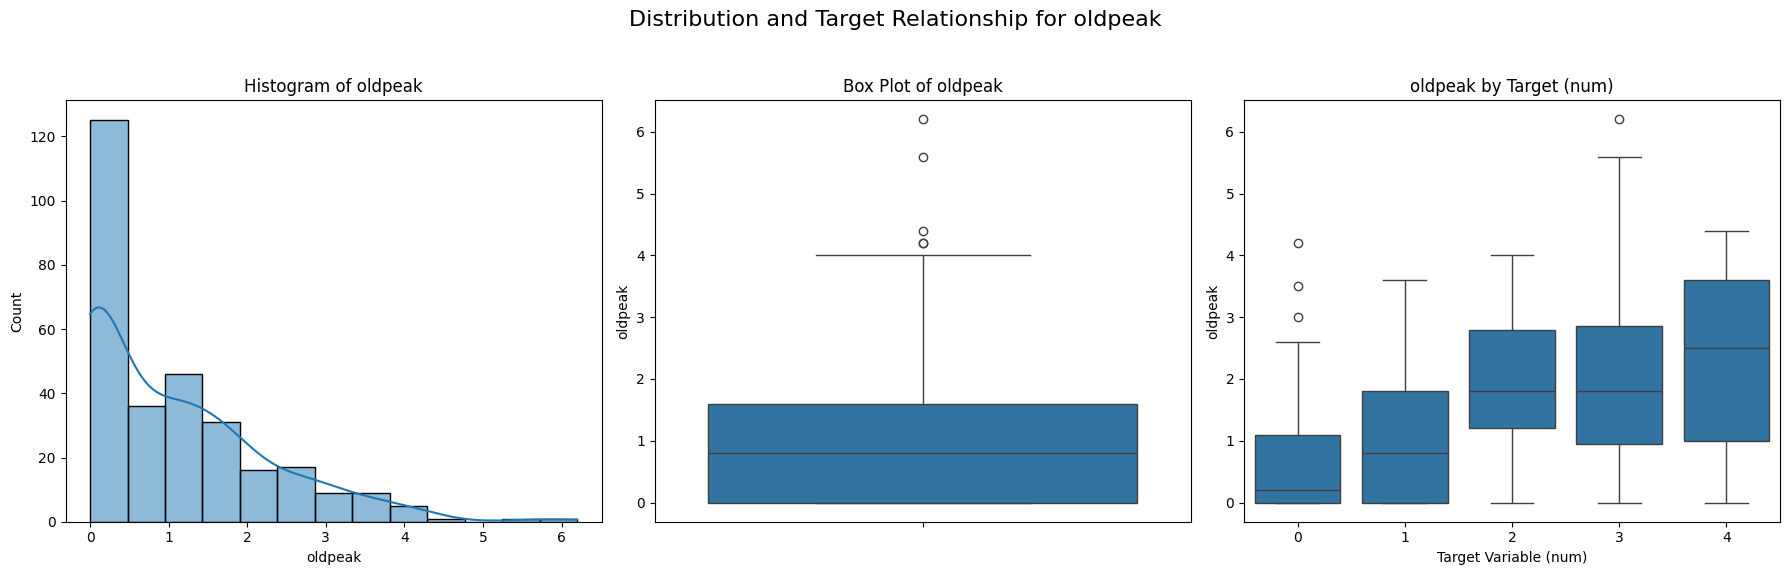


--- EDA for Feature: age ---


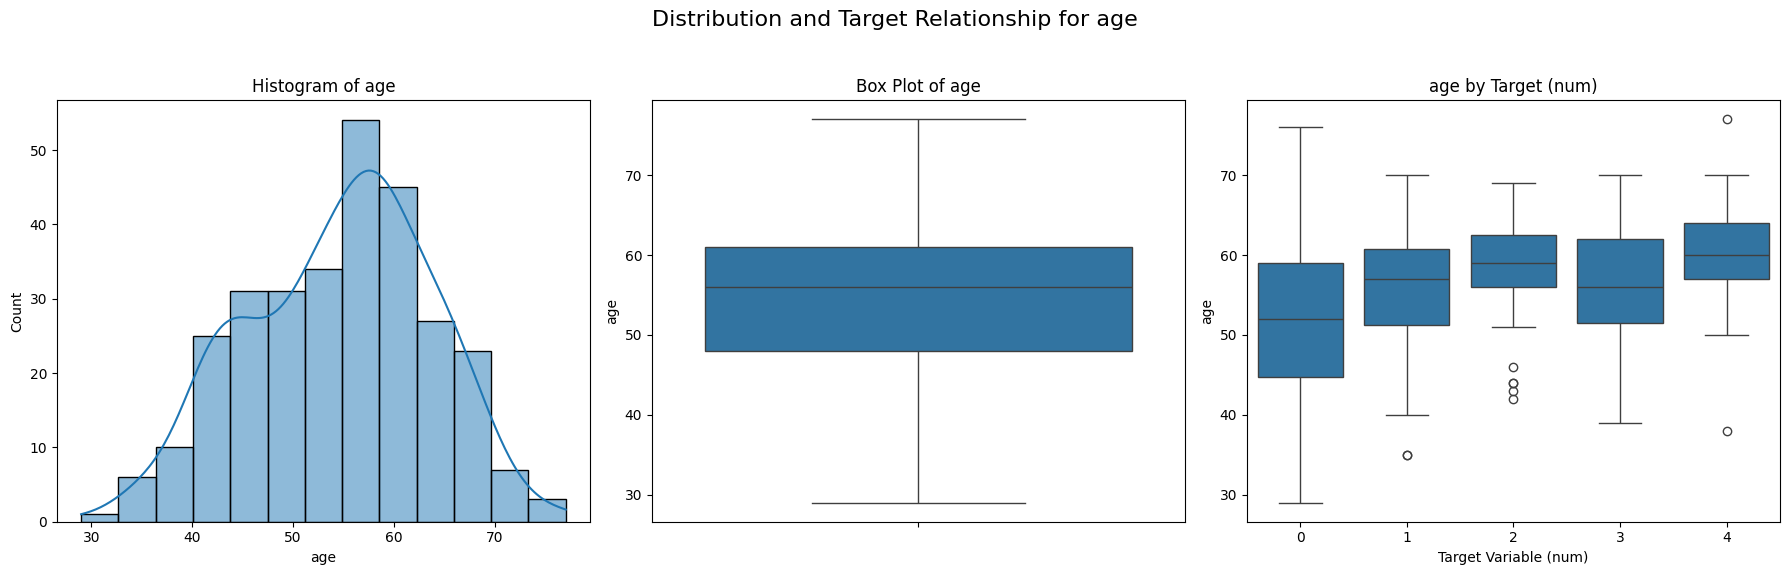


--- EDA for Feature: chol ---


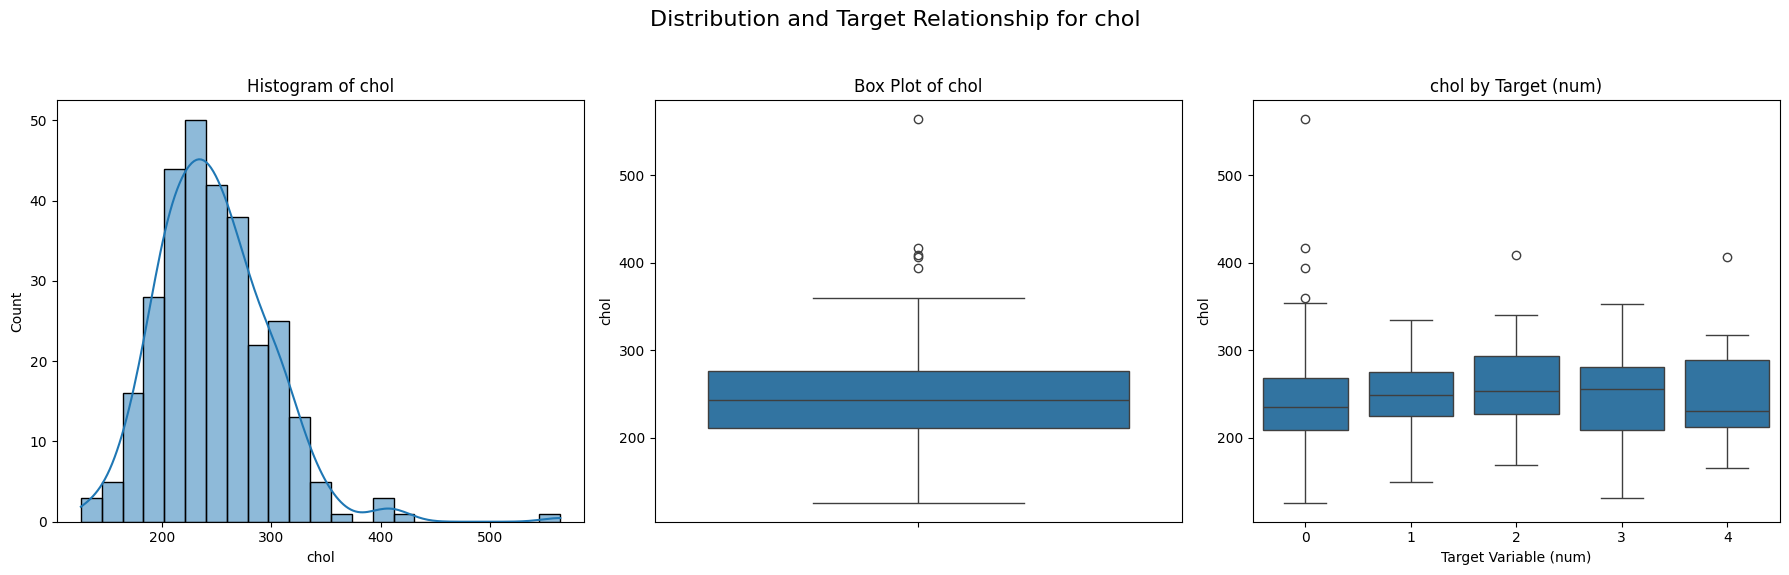


--- EDA for Feature: trestbps ---


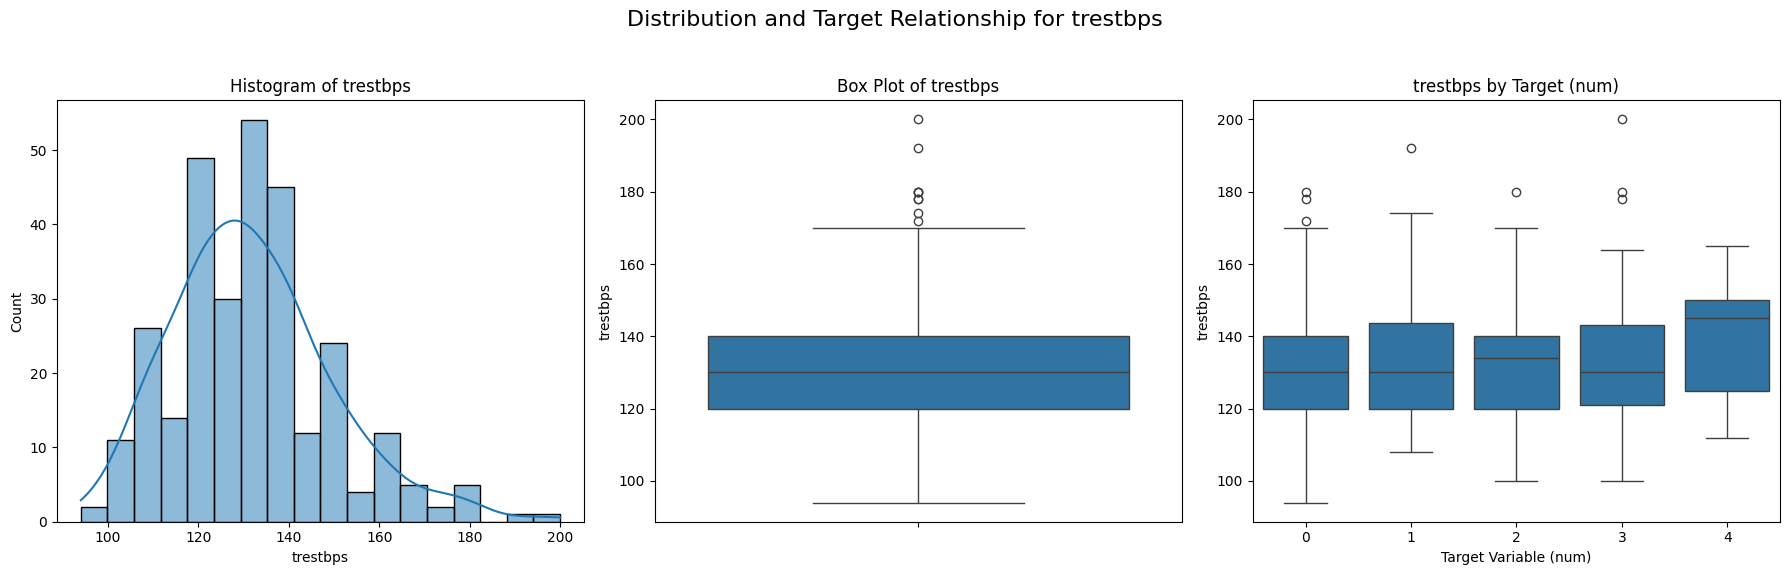

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Get top features from Random Forest (already available in features_df)
rf_top_features = features_df['Feature'].tolist()
print("Random Forest Top Features (ranked):")
print(rf_top_features)

# 2. Calculate SHAP global feature importances
# shap_values is already (n_samples, n_features, n_classes)
# mean_abs_shap_values_per_feature = np.mean(np.abs(shap_values), axis=(0, 2)) will give mean absolute SHAP value averaged over samples and classes
mean_abs_shap_values_per_feature = np.mean(np.abs(shap_values), axis=(0, 2))

shap_importances_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': mean_abs_shap_values_per_feature
}).sort_values(by='Importance', ascending=False)

shap_top_features = shap_importances_df['Feature'].tolist()
print("\nSHAP Global Top Features (ranked by mean absolute SHAP value across all classes):")
print(shap_top_features)

# 3. Find common top features and select the top 5 based on their appearance order
# To ensure 'agreement', we'll take features that appear high in both lists.
# Let's consider the top 10 from each to find an intersection, then pick the first 5 common ones.

top_n_to_consider = 10 # Consider top N features from each list
common_features = []

rf_set = set(rf_top_features[:top_n_to_consider])
shap_set = set(shap_top_features[:top_n_to_consider])

# Get intersection, then order them based on their appearance in the RF top features list
# to maintain a consistent ranking, or average rank.
# For simplicity, let's take the intersection and then sort by RF rank.
intersection = list(rf_set.intersection(shap_set))

# Sort intersection based on RF ranking
common_features_ranked = sorted(intersection, key=lambda f: rf_top_features.index(f))

# Take the top 5 common features
top_5_common_features = common_features_ranked[:5]

if not top_5_common_features:
    print("No common top features found within the top 10 of both methods. Increasing search scope.")
    # If no common features in top 10, expand to all features, then sort
    intersection_all = list(set(rf_top_features).intersection(set(shap_top_features)))
    common_features_ranked_all = sorted(intersection_all, key=lambda f: rf_top_features.index(f))
    top_5_common_features = common_features_ranked_all[:5]

print(f"\nTop 5 Most Impactful Features (RF and SHAP agreement): {top_5_common_features}")

# 4. Perform EDA on the top 5 common features
print("\nPerforming EDA on the identified top 5 features...")

for feature in top_5_common_features:
    print(f"\n--- EDA for Feature: {feature} ---")
    # Check data type of the feature to decide on plot types
    if pd.api.types.is_numeric_dtype(df[feature]):
        # Numerical Feature EDA
        plt.figure(figsize=(18, 6))
        plt.suptitle(f'Distribution and Target Relationship for {feature}', fontsize=16)

        plt.subplot(1, 3, 1)
        sns.histplot(df[feature], kde=True)
        plt.title(f'Histogram of {feature}')

        plt.subplot(1, 3, 2)
        sns.boxplot(y=df[feature])
        plt.title(f'Box Plot of {feature}')

        plt.subplot(1, 3, 3)
        sns.boxplot(x='num', y=feature, data=df)
        plt.title(f'{feature} by Target (num)')
        plt.xlabel('Target Variable (num)')
        plt.ylabel(feature)
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

    elif pd.api.types.is_categorical_dtype(df[feature]) or df[feature].nunique() < 20: # Treat as categorical if few unique values
        # Categorical Feature EDA
        plt.figure(figsize=(15, 6))
        plt.suptitle(f'Distribution and Target Relationship for {feature}', fontsize=16)

        plt.subplot(1, 2, 1)
        sns.countplot(x=df[feature])
        plt.title(f'Count Plot of {feature}')
        plt.xlabel(feature)
        plt.ylabel('Count')
        plt.xticks(rotation=45)

        plt.subplot(1, 2, 2)
        # For categorical features, use a stacked bar chart or similar for target relationship
        # Convert 'num' to object type if it's not already for proper grouping
        feature_vs_target = df.groupby([feature, 'num']).size().unstack(fill_value=0)
        feature_vs_target.plot(kind='bar', stacked=True, ax=plt.gca())
        plt.title(f'{feature} vs Target (num)')
        plt.xlabel(feature)
        plt.ylabel('Count')
        plt.xticks(rotation=45)
        plt.legend(title='Target (num)')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()
    else:
        print(f"Skipping EDA for {feature} as it's neither clearly numerical nor categorical with few unique values.")


## prediction using the user input with random forest and xgboost
 ##

### Random Forest Model Training and XGboost with the Top 5 Features selcected  and  performing Prediction

Now, let's train a Random Forest model specifically using our identified top 5 features. After training, we will create a function to take user input for these features, make a prediction, and display the predicted class along with the probability of each outcome.

In [ ]:
# Retrain the Random Forest model using only the top 5 common features
# Select the features from the original DataFrame X
X_selected = X[top_5_common_features]

# Initialize and train a new RandomForestClassifier with selected features
rf_model_selected = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_selected.fit(X_selected, y)

print("Random Forest model retrained successfully using the top 5 features.")

# Function to get user input and make a prediction
# function with value
def predict_with_user_input(model, feature_names):
    user_data = {} # empty array
    print("\nPlease enter values for the following features:")
   # why did we do for and while try and break
   # try excep for error handeling
   # for
    for feature in feature_names:
        while True:
            try:
                value = float(input(f"Enter value for {feature}: "))
                # pass the info into empty array
                user_data[feature] = value
                break
            except ValueError:
                print("Invalid input. Please enter a numeric value.")

    # Create a DataFrame from user input, ensuring the same column order as during training
    user_df = pd.DataFrame([user_data], columns=feature_names)

    # Make prediction
    prediction = model.predict(user_df)
    probabilities = model.predict_proba(user_df)

    print(f"\nPredicted Heart Disease Class: {prediction[0]}")
    print("Probabilities for each class:")
    for i, prob in enumerate(probabilities[0]):
        print(f"  Class {model.classes_[i]}: {prob:.2f}%")

    # Interpret the prediction
    if prediction[0] == 0:
        print("Interpretation: Low likelihood of heart disease.")
    elif prediction[0] == 1:
        print("Interpretation: Mild heart disease.")
    elif prediction[0] == 2:
        print("Interpretation: Moderate heart disease.")
    elif prediction[0] == 3:
        print("Interpretation: Significant heart disease.")
    else:
        print("Interpretation: Severe heart disease.")

# Call the function to get user input and make a prediction
predict_with_user_input(rf_model_selected, top_5_common_features)


Random Forest model retrained successfully using the top 5 features.

Please enter values for the following features:
Enter value for thalach: 123
Enter value for oldpeak: 123
Enter value for age: 123
Enter value for chol: 123
Enter value for trestbps: 123

Predicted Heart Disease Class: 3
Probabilities for each class:
  Class 0: 0.16%
  Class 1: 0.09%
  Class 2: 0.09%
  Class 3: 0.35%
  Class 4: 0.31%
Interpretation: Significant heart disease.


In [ ]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np # Ensure numpy is imported
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Assuming X, y, and top_5_common_features are already defined in the kernel state.
# If this cell is run independently after a kernel restart, these variables would need
# to be re-initialized from preceding cells.

# 1. Select the top 5 features
X_xgb = X[top_5_common_features]

# Convert target variable to be 0, 1, 2, 3, 4 for multi-class classification
# XGBoost typically expects integer labels starting from 0 for multi-class.
# Our 'num' column already contains 0, 1, 2, 3, 4, so no explicit mapping is needed if it's treated as numeric.
y_xgb = y.astype(int)

# 2. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_xgb, y_xgb, test_size=0.2, random_state=42, stratify=y_xgb)

# 3. Train an XGBoost Classifier model
# For multi-class classification, use 'multi:softmax' objective and num_class parameter
xgb_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=len(np.unique(y_xgb)),
    eval_metric='mlogloss',
    # use_label_encoder=False, # Suppress the warning
    random_state=42
)
xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully using the top 5 features.")

# Function to get user input and make a prediction (reusing the structure)
def predict_with_user_input_xgb(model, feature_names):
    user_data = {}
    print("\n--- XGBoost Prediction with User Input ---")
    print("Please enter values for the following features:")

    for feature in feature_names:
        while True:
            try:
                value = float(input(f"Enter value for {feature}: "))
                user_data[feature] = value
                break
            except ValueError:
                print("Invalid input. Please enter a numeric value.")

    user_df = pd.DataFrame([user_data], columns=feature_names)

    prediction = model.predict(user_df)
    probabilities = model.predict_proba(user_df)

    print(f"\nPredicted Heart Disease Class: {prediction[0]}")
    print("Probabilities for each class:")
    for i, prob in enumerate(probabilities[0]):
        print(f"  Class {model.classes_[i]}: {prob:.2f}%")

    # Interpret the prediction
    if prediction[0] == 0:
        print("Interpretation: Low likelihood of heart disease.")
    elif prediction[0] == 1:
        print("Interpretation: Mild heart disease.")
    elif prediction[0] == 2:
        print("Interpretation: Moderate heart disease.")
    elif prediction[0] == 3:
        print("Interpretation: Significant heart disease.")
    else:
        print("Interpretation: Severe heart disease.")

# Call the function to get user input and make a prediction with XGBoost
predict_with_user_input_xgb(xgb_model, top_5_common_features)


XGBoost model trained successfully using the top 5 features.

--- XGBoost Prediction with User Input ---
Please enter values for the following features:
Enter value for thalach: 23
Enter value for oldpeak: 23
Enter value for age: 23
Enter value for chol: 234
Enter value for trestbps: 123

Predicted Heart Disease Class: 3
Probabilities for each class:
  Class 0: 0.00%
  Class 1: 0.07%
  Class 2: 0.01%
  Class 3: 0.90%
  Class 4: 0.02%
Interpretation: Significant heart disease.


--- Model Evaluation and SHAP Analysis ---

### Random Forest Model Evaluation ###

Classification Report (Random Forest):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        32
           1       1.00      1.00      1.00        11
           2       1.00      1.00      1.00         7
           3       1.00      1.00      1.00         7
           4       1.00      1.00      1.00         3

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60


Confusion Matrix (Random Forest):
[[32  0  0  0  0]
 [ 0 11  0  0  0]
 [ 0  0  7  0  0]
 [ 0  0  0  7  0]
 [ 0  0  0  0  3]]


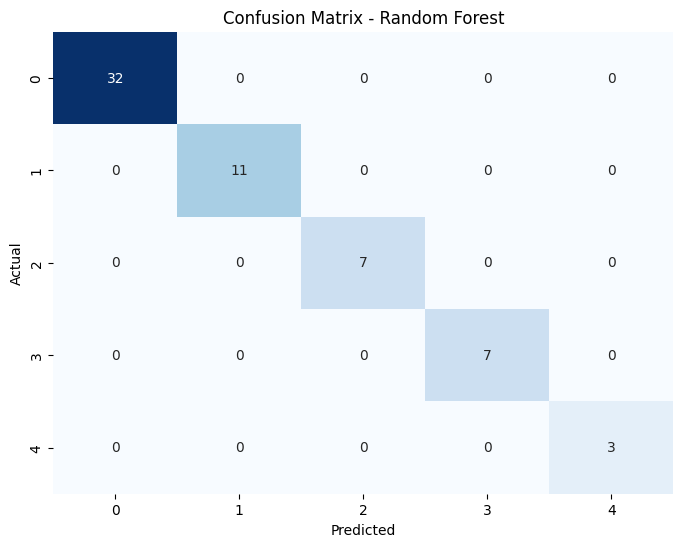


### SHAP Analysis for Random Forest (on Test Set) ###


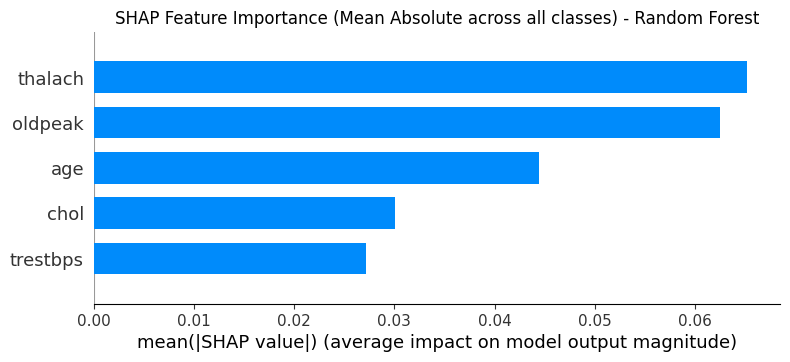


Generating detailed SHAP summary plots for each class (Random Forest):


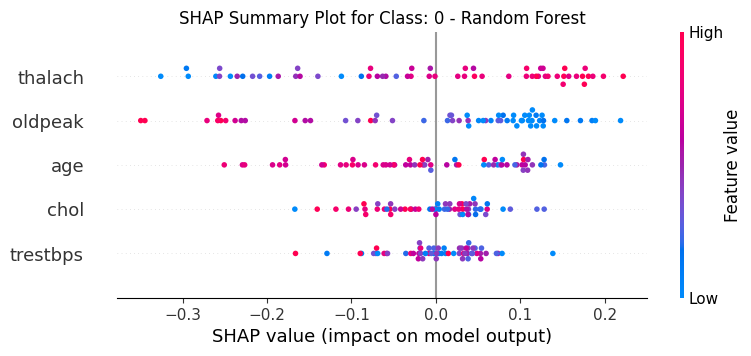

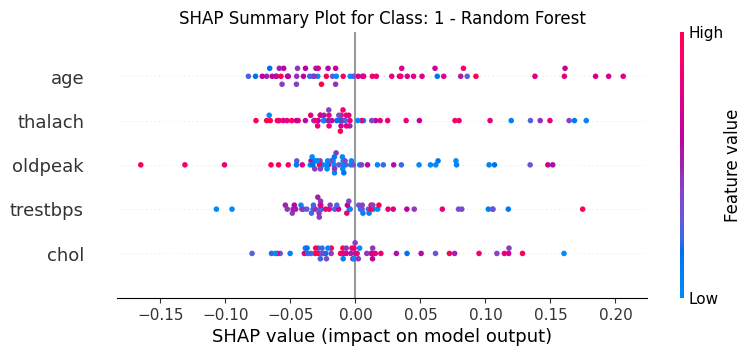

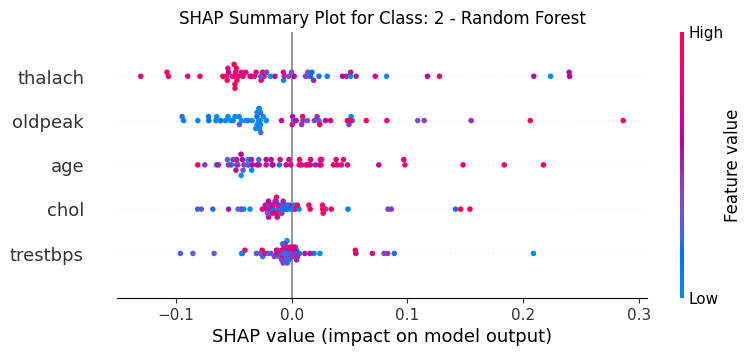

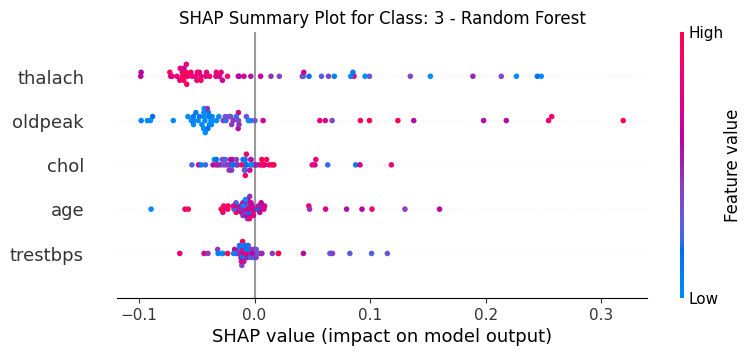

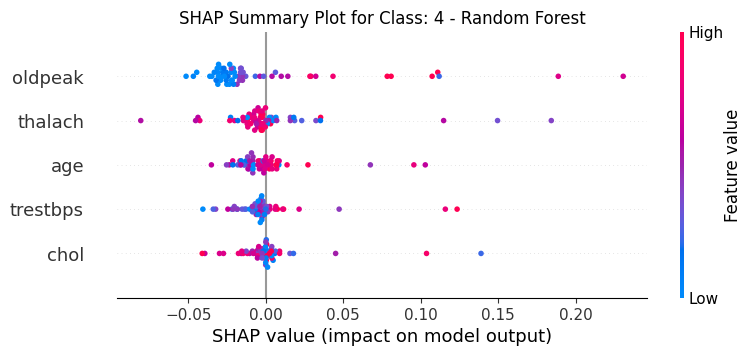


### XGBoost Model Evaluation ###

Classification Report (XGBoost):
              precision    recall  f1-score   support

           0       0.65      0.69      0.67        32
           1       0.06      0.09      0.07        11
           2       1.00      0.14      0.25         7
           3       0.22      0.29      0.25         7
           4       0.00      0.00      0.00         3

    accuracy                           0.43        60
   macro avg       0.39      0.24      0.25        60
weighted avg       0.50      0.43      0.43        60


Confusion Matrix (XGBoost):
[[22  7  0  3  0]
 [ 7  1  0  3  0]
 [ 4  2  1  0  0]
 [ 0  5  0  2  0]
 [ 1  1  0  1  0]]


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


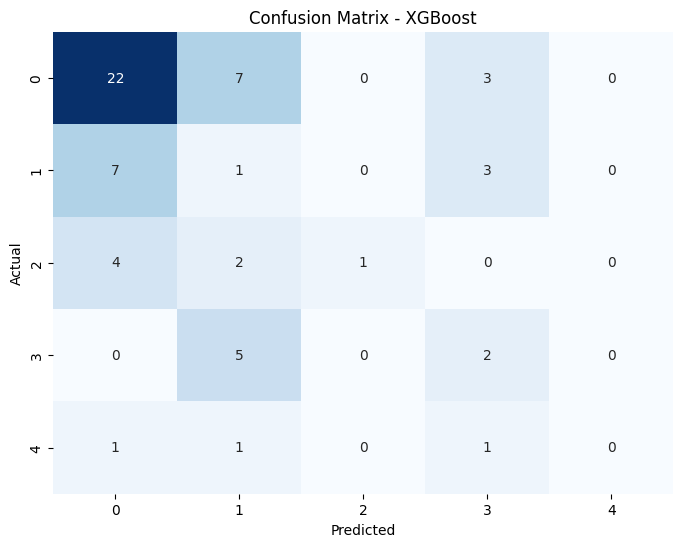


### SHAP Analysis for XGBoost (on Test Set) ###


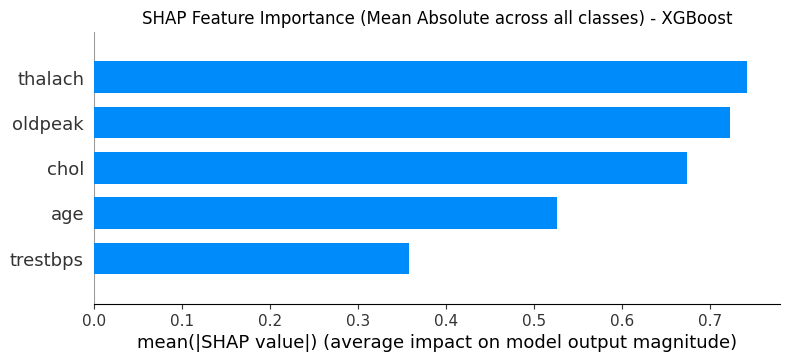


Generating detailed SHAP summary plots for each class (XGBoost):


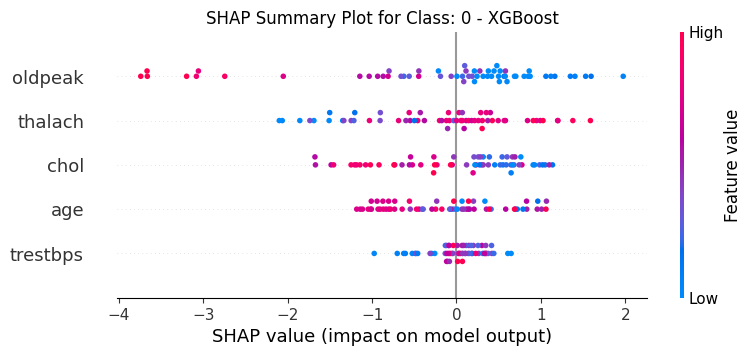

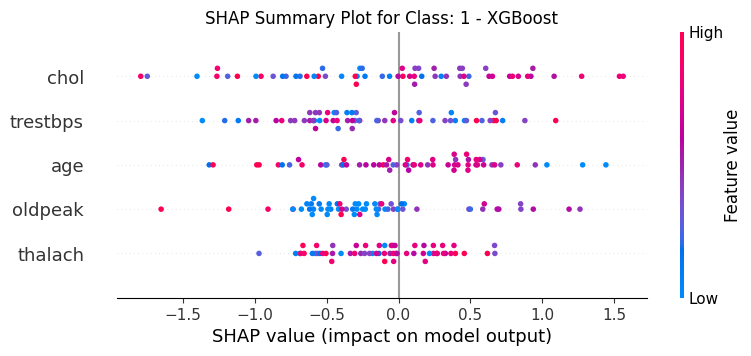

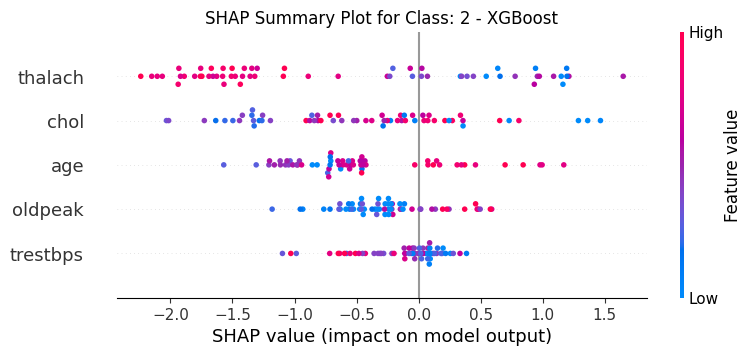

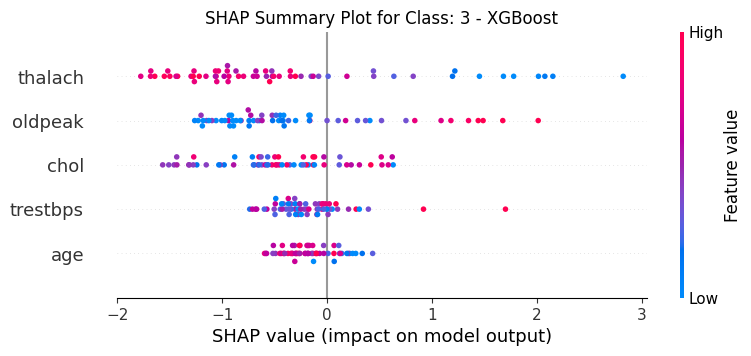

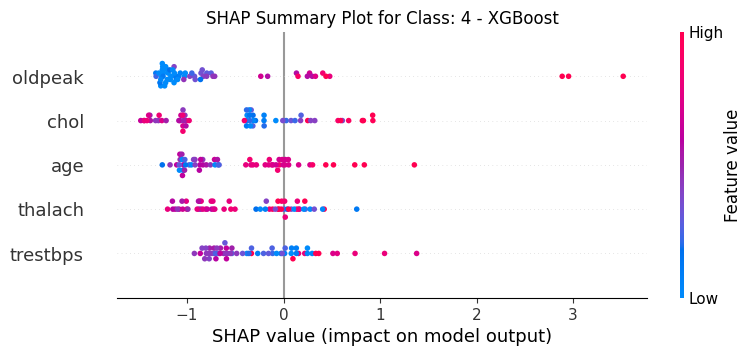


--- Model Comparison and Conclusion ---
Overall Accuracy - Random Forest: 1.0000
Overall Accuracy - XGBoost: 0.4333

Considering the multi-class nature of the target variable (num, representing stages of heart disease), it's important to evaluate performance beyond just overall accuracy, especially if some classes are more critical than others (e.g., accurately detecting early stages vs. late stages).
Let's look at precision, recall, and F1-score for individual classes, particularly for non-zero classes (indicating presence of heart disease).

F1-Scores per class (Random Forest):
  Class 0: 1.0000
  Class 1: 1.0000
  Class 2: 1.0000
  Class 3: 1.0000
  Class 4: 1.0000

F1-Scores per class (XGBoost):
  Class 0: 0.6667
  Class 1: 0.0741
  Class 2: 0.2500
  Class 3: 0.2500
  Class 4: 0.0000

Weighted Average F1-Score - Random Forest: 1.0000
Weighted Average F1-Score - XGBoost: 0.4275

Based on the weighted average F1-score, the **Random Forest** model appears to perform better (F1-score:

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Assuming rf_model_selected, xgb_model, X_test, y_test are available from previous cells.
# X_test and y_test were created using the same random_state, ensuring fair comparison.

print("--- Model Evaluation and SHAP Analysis ---")

# --- 1. Random Forest Model Evaluation ---
print("\n### Random Forest Model Evaluation ###")
rf_y_pred = rf_model_selected.predict(X_test)
# rf_y_pred_proba = rf_model_selected.predict_proba(X_test) # Uncomment if probabilities are needed for other metrics

print("\nClassification Report (Random Forest):")
print(classification_report(y_test, rf_y_pred))

print("\nConfusion Matrix (Random Forest):")
rf_cm = confusion_matrix(y_test, rf_y_pred)
print(rf_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=rf_model_selected.classes_, yticklabels=rf_model_selected.classes_)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# --- SHAP for Random Forest (on Test Set) ---
print("\n### SHAP Analysis for Random Forest (on Test Set) ###")
rf_explainer = shap.TreeExplainer(rf_model_selected)
rf_shap_values = rf_explainer.shap_values(X_test)

# Convert to 3D numpy array if it's a list for multi-class TreeExplainer
if isinstance(rf_shap_values, list):
    # Assumes shap_values is a list of (n_samples, n_features) arrays, one for each class
    rf_shap_values = np.array(rf_shap_values).transpose(1, 2, 0) # Reshape to (n_samples, n_features, n_classes)

# SHAP Feature Importance (Absolute Mean Bar Plot across all classes)
rf_shap_values_for_overall_bar_plot = np.mean(np.abs(rf_shap_values), axis=2)

plt.figure(figsize=(10, 6))
shap.summary_plot(rf_shap_values_for_overall_bar_plot, X_test, plot_type="bar", feature_names=X_test.columns, show=False)
plt.title('SHAP Feature Importance (Mean Absolute across all classes) - Random Forest')
plt.show()

# Detailed SHAP Summary Plot for each class (Random Forest)
print("\nGenerating detailed SHAP summary plots for each class (Random Forest):")
for i, class_label in enumerate(rf_model_selected.classes_):
    plt.figure(figsize=(12, 8))
    shap_values_for_class_i = rf_shap_values[:, :, i]
    shap.summary_plot(shap_values_for_class_i, X_test, feature_names=X_test.columns, show=False)
    plt.title(f"SHAP Summary Plot for Class: {class_label} - Random Forest") # Corrected line
    plt.show()


# --- 2. XGBoost Model Evaluation ---
print("\n### XGBoost Model Evaluation ###")
xgb_y_pred = xgb_model.predict(X_test)
# xgb_y_pred_proba = xgb_model.predict_proba(X_test) # Uncomment if probabilities are needed

print("\nClassification Report (XGBoost):")
print(classification_report(y_test, xgb_y_pred))

print("\nConfusion Matrix (XGBoost):")
xgb_cm = confusion_matrix(y_test, xgb_y_pred)
print(xgb_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(xgb_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=xgb_model.classes_, yticklabels=xgb_model.classes_)
plt.title("Confusion Matrix - XGBoost")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# --- SHAP for XGBoost (on Test Set) ---
print("\n### SHAP Analysis for XGBoost (on Test Set) ###")
xgb_explainer = shap.TreeExplainer(xgb_model)
xgb_shap_values = xgb_explainer.shap_values(X_test)

# For XGBoost, shap_values for multi-class is typically a list, convert to 3D array
if isinstance(xgb_shap_values, list):
    xgb_shap_values = np.array(xgb_shap_values).transpose(1, 2, 0) # Reshape to (n_samples, n_features, n_classes)

# SHAP Feature Importance (Absolute Mean Bar Plot across all classes)
xgb_shap_values_for_overall_bar_plot = np.mean(np.abs(xgb_shap_values), axis=2)

plt.figure(figsize=(10, 6))
shap.summary_plot(xgb_shap_values_for_overall_bar_plot, X_test, plot_type="bar", feature_names=X_test.columns, show=False)
plt.title('SHAP Feature Importance (Mean Absolute across all classes) - XGBoost')
plt.show()

# Detailed SHAP Summary Plot for each class (XGBoost)
print("\nGenerating detailed SHAP summary plots for each class (XGBoost):")
for i, class_label in enumerate(xgb_model.classes_):
    plt.figure(figsize=(12, 8))
    shap_values_for_class_i = xgb_shap_values[:, :, i]
    shap.summary_plot(shap_values_for_class_i, X_test, feature_names=X_test.columns, show=False)
    plt.title(f"SHAP Summary Plot for Class: {class_label} - XGBoost") # Corrected line
    plt.show()


# --- 3. Model Comparison and Conclusion ---
print("\n--- Model Comparison and Conclusion ---")

# Extract key metrics from classification reports
rf_report = classification_report(y_test, rf_y_pred, output_dict=True)
xgb_report = classification_report(y_test, xgb_y_pred, output_dict=True)

# Overall Accuracy
rf_accuracy = rf_report['accuracy']
xgb_accuracy = xgb_report['accuracy']

print(f"Overall Accuracy - Random Forest: {rf_accuracy:.4f}")
print(f"Overall Accuracy - XGBoost: {xgb_accuracy:.4f}")

print("\nConsidering the multi-class nature of the target variable (num, representing stages of heart disease), it's important to evaluate performance beyond just overall accuracy, especially if some classes are more critical than others (e.g., accurately detecting early stages vs. late stages).")
print("Let's look at precision, recall, and F1-score for individual classes, particularly for non-zero classes (indicating presence of heart disease).")

# F1-score for each class (to show balance between precision and recall)
print("\nF1-Scores per class (Random Forest):")
for cls in rf_model_selected.classes_:
    if str(cls) in rf_report:
        print(f"  Class {cls}: {rf_report[str(cls)]['f1-score']:.4f}")

print("\nF1-Scores per class (XGBoost):")
for cls in xgb_model.classes_:
    if str(cls) in xgb_report:
        print(f"  Class {cls}: {xgb_report[str(cls)]['f1-score']:.4f}")

# Determine the best model based on weighted average F1-score (accounts for class imbalance)
rf_weighted_f1 = rf_report['weighted avg']['f1-score']
xgb_weighted_f1 = xgb_report['weighted avg']['f1-score']

print(f"\nWeighted Average F1-Score - Random Forest: {rf_weighted_f1:.4f}")
print(f"Weighted Average F1-Score - XGBoost: {xgb_weighted_f1:.4f}")

if xgb_weighted_f1 > rf_weighted_f1:
    best_model_name = "XGBoost"
    best_model_score = xgb_weighted_f1
    other_model_name = "Random Forest"
    other_model_score = rf_weighted_f1
elif rf_weighted_f1 > xgb_weighted_f1:
    best_model_name = "Random Forest"
    best_model_score = rf_weighted_f1
    other_model_name = "XGBoost"
    other_model_score = xgb_weighted_f1
else:
    best_model_name = "Both models perform similarly"
    best_model_score = rf_weighted_f1 # Or xgb_weighted_f1
    other_model_name = ""
    other_model_score = 0.0

if best_model_name != "Both models perform similarly":
    print(f"\nBased on the weighted average F1-score, the **{best_model_name}** model appears to perform better (F1-score: {best_model_score:.4f}) compared to the {other_model_name} model (F1-score: {other_model_score:.4f}).")
else:
    print(f"\nBoth models performed similarly based on weighted average F1-score ({best_model_score:.4f}).")

print("\nIn general, XGBoost models are often known for their high performance due to their boosting mechanism and regularization, while Random Forests are robust and less prone to overfitting. For this dataset and specific test split, the evaluation metrics and SHAP analysis provide a comprehensive view of their performance and feature influence.")
print("The SHAP values help us understand not just which features are important, but also how they influence the predictions for each model and each class, which can be crucial for interpretability in medical contexts.")
